# 05 — Hybride : graphe de prérequis + niveau + contenu + collaboratif

In [1]:
import sys, os
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data_loader import load, split_per_user, save_processed
DATA = "../data/raw/interactions_real_rich_processed.csv"
df = load(DATA)
train, test = split_per_user(df)

In [2]:
from src.pipeline import build, tune_alpha
alpha = tune_alpha(train)
S = build(train, alpha)
print('alpha =', alpha, '| arêtes du graphe :', S.G.number_of_edges())

  alpha=0.0  NDCG@5(val)=0.1364
  alpha=0.2  NDCG@5(val)=0.1298
  alpha=0.4  NDCG@5(val)=0.1130
  alpha=0.5  NDCG@5(val)=0.1037
  alpha=0.6  NDCG@5(val)=0.0942
  alpha=0.8  NDCG@5(val)=0.0789
  alpha=1.0  NDCG@5(val)=0.0678
alpha = 0 | arêtes du graphe : 177


Text(0.5, 1.0, 'Graphe de prérequis appris')

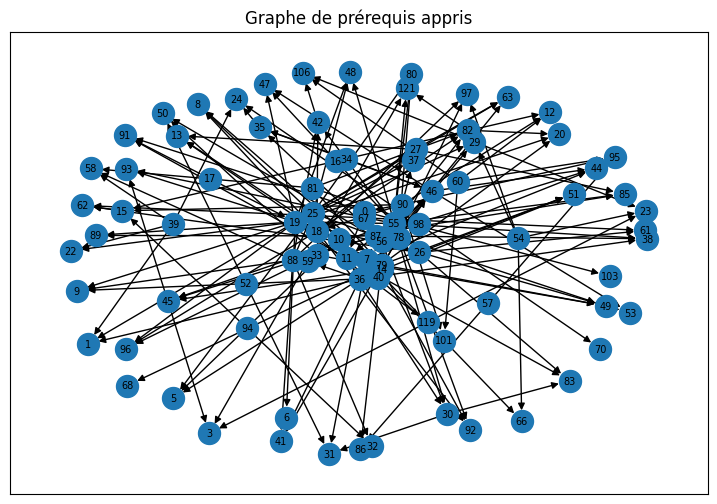

In [3]:
import networkx as nx
from src.knowledge_graph import save_knowledge
save_knowledge(S.G, S.sm, '../data/knowledge')
G = S.G.subgraph([n for n in S.G if S.G.degree(n) > 0])
plt.figure(figsize=(9,6)); nx.draw_networkx(G, pos=nx.spring_layout(G, seed=1), node_size=250, font_size=7, arrows=True); plt.title('Graphe de prérequis appris')

In [4]:
users = S.sm.user_count.sort_values()
rich, mid = users.index[-1], users.index[len(users)//2]
print('--- A (cold start) ---'); display(S.hyb.recommend(S.sm.get_history(mid).iloc[:1], k=5))
print('--- B (historique riche) ---'); display(S.hyb.recommend(S.sm.get_history(rich), k=5))
print('--- C (difficulté <= 0.5) ---'); display(S.hyb.recommend(S.sm.get_history(rich), k=5, max_difficulty=0.5))

--- A (cold start) ---


,skill_id_new,score,explication
0,10,0.835,aucun prérequis ; difficulté 0.13 ≤ niveau est...
1,40,0.835,aucun prérequis ; difficulté 0.09 ≤ niveau est...
2,14,0.835,aucun prérequis ; difficulté 0.22 ≤ niveau est...
3,56,0.835,aucun prérequis ; difficulté 0.17 ≤ niveau est...
4,17,0.835,aucun prérequis ; difficulté 0.07 ≤ niveau est...


--- B (historique riche) ---


,skill_id_new,score,explication
0,94,0.881,aucun prérequis ; difficulté 0.09 ≤ niveau est...
1,67,0.861,aucun prérequis ; difficulté 0.10 ≤ niveau est...
2,88,0.858,aucun prérequis ; difficulté 0.09 ≤ niveau est...
3,47,0.858,"prérequis [19, 46, 55] acquis ; difficulté 0.5..."
4,81,0.853,aucun prérequis ; difficulté 0.17 ≤ niveau est...


--- C (difficulté <= 0.5) ---


,skill_id_new,score,explication
0,94,0.881,aucun prérequis ; difficulté 0.09 ≤ niveau est...
1,67,0.861,aucun prérequis ; difficulté 0.10 ≤ niveau est...
2,88,0.858,aucun prérequis ; difficulté 0.09 ≤ niveau est...
3,81,0.853,aucun prérequis ; difficulté 0.17 ≤ niveau est...
4,119,0.851,prérequis [19] acquis ; difficulté 0.26 ≤ nive...
